# Week 3: Volatility
Treating volatility as a static constant is the most common beginner error.

In [1]:
# Load your data from ../data/ (see the setup notebook)
from pathlib import Path
import pandas as pd

TICKERS = ["GLD", "TIP"]
data_dir = Path("../data")
prices = {}

for ticker in TICKERS:
    df = pd.read_csv(data_dir / f"{ticker}.csv", parse_dates=["Date"])
    prices[ticker] = df.set_index("Date").sort_index()

prices[TICKERS[0]].tail()

,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2025-12-24,411.929993,411.929993,412.630005,408.829987,412.250000,6718400
2025-12-26,416.739990,416.739990,418.450012,414.750000,416.480011,10476200
2025-12-29,398.600006,398.600006,403.760010,395.329987,403.660004,20679200
2025-12-30,398.890015,398.890015,403.799988,398.559998,403.600006,10179000
2025-12-31,396.309998,396.309998,400.130005,395.589996,398.600006,10194700


## Visual
Plot the **21-day rolling annualized volatility** for both assets. Mark the **three highest spikes** and
identify the real-world events that caused them. (You'll have to calculate it from returns which you found in week 1)

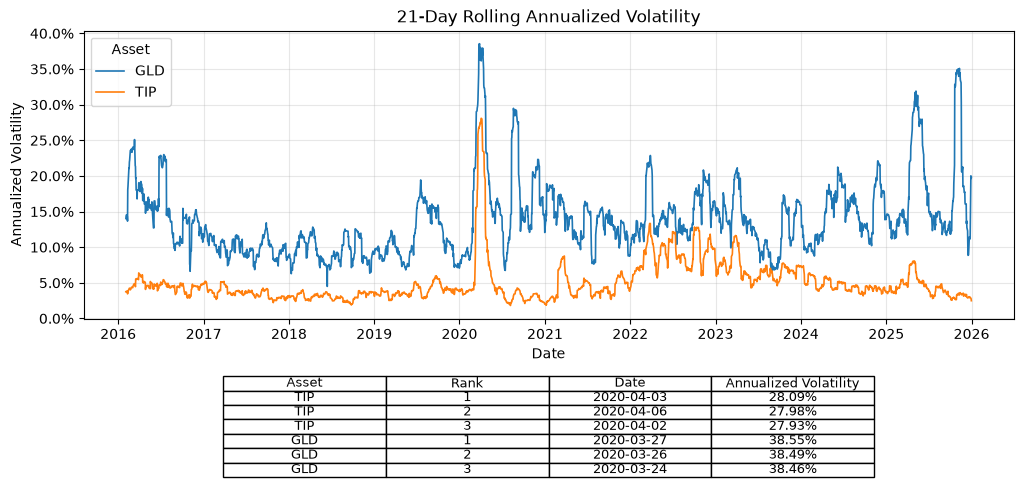

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

TICKERS = ["GLD", "TIP"]

# daily returns
returns = pd.DataFrame({
    ticker: prices[ticker]["Adj Close"].pct_change()
    for ticker in TICKERS
})

# 21-day rolling annualized volatility
rolling_vol = returns.rolling(window=21).std() * np.sqrt(252)

# top three volatility observations for each asset
top_tip = rolling_vol["TIP"].nlargest(3)
top_gld = rolling_vol["GLD"].nlargest(3)

# graph
fig, ax = plt.subplots(figsize=(12, 6))

# rolling volatility
for ticker in TICKERS:
    ax.plot(
        rolling_vol.index,
        rolling_vol[ticker],
        label=ticker,
        linewidth=1.2
    )

ax.set_title("21-Day Rolling Annualized Volatility")
ax.set_xlabel("Date")
ax.set_ylabel("Annualized Volatility")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(True, alpha=0.3)
ax.legend(title="Asset")

# table
table_data = []

for ticker, top_spikes in [("TIP", top_tip), ("GLD", top_gld)]:
    for rank, (date, volatility) in enumerate(top_spikes.items(), start=1):
        table_data.append([
            ticker,
            rank,
            date.strftime("%Y-%m-%d"),
            f"{volatility:.2%}"
        ])

# Add table beneath graph
table = ax.table(
    cellText=table_data,
    colLabels=[
        "Asset",
        "Rank",
        "Date",
        "Annualized Volatility"
    ],
    cellLoc="center",
    loc="bottom",
    bbox=[0.15, -0.55, 0.7, 0.35]
)

table.auto_set_font_size(False)
table.set_fontsize(9)

# Adjust spacing
fig.subplots_adjust(bottom=0.40)

plt.show()





| Asset | Spike date | Event |
|---|---|---|
| TIP | 04/03/2020 | Both the dash for cash event, and the lower expected interest rates fell, which decreased real yield. TIPS encountered a period of reduced liquidity here from dash for cash, and lower expected inflation decreased TIPs percieved value. |
| TIP | 04/06/2020 | These dates all experiences the same climates. |
| TIP | 04/02/2020 | All three spike days are directly related. |
| GLD | 03/27/2020 | Covid-19 pandemic- investors mass sold their GLD for liquidity to cover immediate cash needs. GLD experiences mass drop in value from this, but also regains some value over this 21 day period. |
| GLD | 03/26/2020 | All three spike dates experienced the same falls to value, thus sharing high volatility.|
| GLD | 03/24/2020 | Same as above. |

## The Check
Test for volatility clustering by plotting the **autocorrelation of absolute returns**
(proving that "big days follow big days").

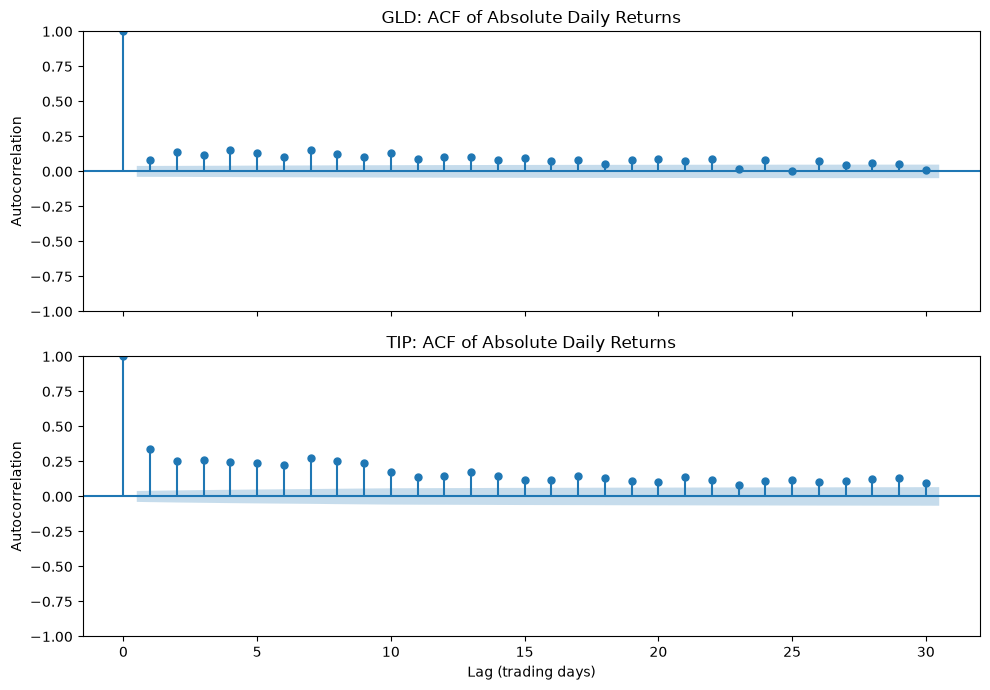

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(len(TICKERS), 1, figsize=(10, 7), sharex=True)
axes = np.atleast_1d(axes)

for ticker, ax in zip(TICKERS, axes):
    plot_acf(
        returns[ticker].abs().dropna(),
        lags=30,
        alpha=0.05,
        ax=ax,
        title=f"{ticker}: ACF of Absolute Daily Returns",
    )
    ax.set_ylabel("Autocorrelation")

axes[-1].set_xlabel("Lag (trading days)")
fig.tight_layout()
plt.show()

## The Paragraph
> **Does market panic hit both assets simultaneously, or do they experience isolated crises?**

Both GLD and TIP experienced an extremely volatile period in early 2020, influenced by the same pandemic economic crash. However, while GLD experienced volatility mostly out of rapid liquidation lowering prices, TIPS experiended a delayed volatile period due to the decreased liquidity specific to TIPS. Both suffered due to lower expected inflation as TIP value directly decreases as expected inflation decreases, and GLD becomes a less appealing asset when inflation is low and the market is propped up by low interest rates.

---
**Done?** Restart the kernel and **Run All** to check everything runs top to bottom, then commit
(navigate into your project folder in the terminal first):

```bash
git add .
git commit -m "Week 6: volatility"
git push
```